# Árbol de Decisión - Champions League
### Predicción de Campeón 

In [ ]:
!pip install scikit-learn pandas matplotlib
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn import metrics

In [2]:
champions = pd.read_csv('champions_league_dataset_v2.csv')
champions.head()

,equipo,temporada,puntos_liga,goles_favor_liga,goles_contra_liga,diferencia_goles_liga,posicion_liga,partidos_ganados_ucl,partidos_empatados_ucl,partidos_perdidos_ucl,...,fase_maxima_temp_anterior,indice_forma_ultimos5,lesiones_clave,edad_media_plantilla,jugadores_internacionales,goles_fuera_casa_ucl,clean_sheets_ucl,partidos_remontada,racha_victorias_max,campeón
0,Real Madrid,2022-23,78,75,36,39,2,10,3,2,...,campeón,4.2,1,27.4,22,18,4,2,8,1.0
1,Manchester City,2022-23,89,94,33,61,1,11,2,1,...,semifinal,4.6,0,26.1,24,17,5,1,9,0.0
2,Inter Milan,2022-23,84,67,35,32,3,9,3,2,...,cuartos,3.8,2,28.9,18,9,5,1,6,0.0
3,AC Milan,2022-23,70,54,35,19,4,6,3,5,...,semifinal,3.2,3,27.6,17,6,3,0,4,0.0
4,Real Madrid,2021-22,86,80,31,49,1,11,2,1,...,semifinal,4.4,0,27.1,21,21,4,3,9,1.0


In [ ]:

champions['xG_diferencia'] = champions['xG_diferencia'].astype(str).str.replace('\u2212', '-', regex=False)
champions['xG_diferencia'] = pd.to_numeric(champions['xG_diferencia'], errors='coerce')

# Quedarnos solo con filas que tienen resultado 
champions = champions[champions['campeón'].isin([0, 1])].copy()
champions['campeón'] = champions['campeón'].astype(int)

In [ ]:
feature_cols = ['partidos_ganados_ucl', 'goles_favor_ucl', 'goles_contra_ucl',
                'posesion_promedio', 'xG_favor', 'xG_diferencia',
                'valor_mercado_plantilla_M_EUR', 'titulos_ucl_historicos',
                'indice_forma_ultimos5', 'clean_sheets_ucl']

X = champions[feature_cols]   
y = champions['campeón']     

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)

In [6]:
# Crear el clasificador
clf = DecisionTreeClassifier()

# Entrenar
clf = clf.fit(X_train, y_train)

# Predecir
y_pred = clf.predict(X_test)

In [7]:
print("Accuracy:", metrics.accuracy_score(y_test, y_pred))

Accuracy: 0.8181818181818182


In [8]:
clf = DecisionTreeClassifier(criterion="entropy", max_depth=3)
clf = clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

print("Accuracy:", metrics.accuracy_score(y_test, y_pred))

Accuracy: 0.9090909090909091


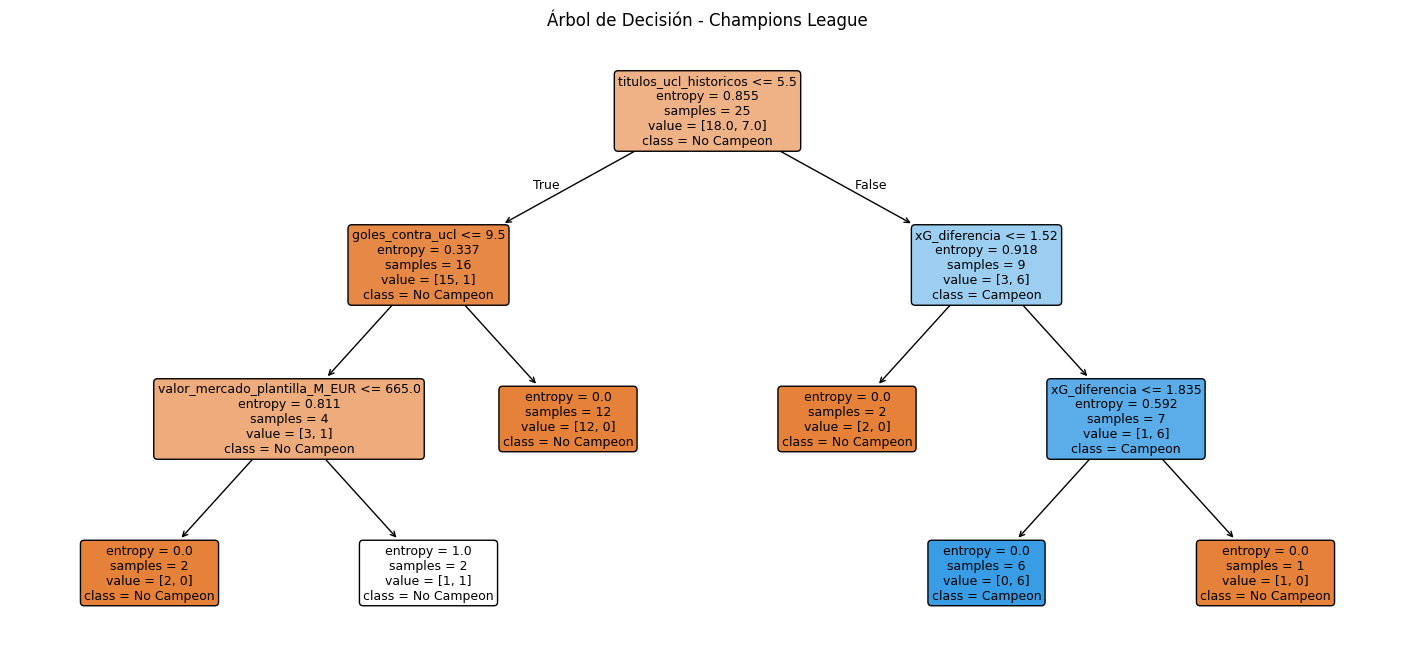

In [10]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(18, 8))
plot_tree(clf,
          feature_names=feature_cols,
          class_names=['No Campeon', 'Campeon'],
          filled=True,
          rounded=True,
          fontsize=9)

plt.title("Árbol de Decisión - Champions League")
plt.savefig('champions_tree.png', dpi=150, bbox_inches='tight')
plt.show()

In [12]:
champions['prediccion'] = clf.predict(X)
campeon = champions[champions['prediccion'] == 1][['equipo', 'temporada']]
print(campeon)

           equipo temporada
0     Real Madrid   2022-23
4     Real Madrid   2021-22
12  Bayern Munich   2019-20
16      Liverpool   2018-19
20    Real Madrid   2017-18
24    Real Madrid   2016-17
